In [56]:
from pathlib import Path
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "Scripts/python/jupyter/lib/set_envs.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abre el notebook desde un directorio del repositorio Athena.")
sys.path.insert(0, str(ROOT / "Scripts/python/jupyter"))
from lib.set_envs import DB_CONFIG

import hashlib
import io
import json
import math
import unicodedata
import uuid
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2
from matplotlib.colors import LinearSegmentedColormap
from pydantic import BaseModel, Field
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

### CONSTANTES
LIST_AREAS = [3] #[1, 2, 3]
AREAS_IMPLEMENTADAS = (1, 2, 3)
SUBIR_DB = True
REEMPLAZAR_EXISTENTE = False
NAMES = [
    "Sofía", "Mateo", "Valentina", "Santiago", "Camila",
    "Sebastián", "Mariana", "Leonardo", "Isabella", "Diego",
    "Lucía", "Emiliano", "Daniela", "Alejandro", "Renata",
    "Nicolás", "Victoria", "Gabriel", "Natalia", "Daniel",
    "Regina", "Samuel", "Ximena", "Andrés", "Fernanda",
    "Rodrigo", "Paula", "Adrián", "Carolina", "David",
    "Andrea", "Joaquín", "Jimena", "Eduardo", "Elena",
    "Fernando", "Ana", "Ricardo", "Gabriela", "Manuel",
    "Claudia", "Javier", "Patricia", "Óscar", "Mónica",
    "Iván", "Verónica", "Hugo", "Alejandra", "Pablo",
]

LAST_NAMES = [
    "García", "Hernández", "Martínez", "López", "González",
    "Pérez", "Rodríguez", "Sánchez", "Ramírez", "Cruz",
    "Flores", "Gómez", "Morales", "Vázquez", "Reyes",
    "Jiménez", "Torres", "Díaz", "Gutiérrez", "Ruiz",
    "Mendoza", "Aguilar", "Ortiz", "Moreno", "Castillo",
    "Romero", "Álvarez", "Méndez", "Chávez", "Rivera",
    "Juárez", "Ramos", "Domínguez", "Herrera", "Medina",
    "Castro", "Vargas", "Guzmán", "Rojas", "Velázquez",
    "Contreras", "Salazar", "Luna", "Ortega", "Santiago",
    "Guerrero", "Estrada", "Bautista", "Cortés", "Navarro",
]

STATUS_DIC = {
    1: "PENDING",
    2: "EXTRACTED",
    3: "CLASSIFIED",
    4: "COMPLETED"
}

TYPE_USER_DIC = {
    1: "ENTRENAMIENTO",
    2: "VALIDACION",
    3: "TEST",
    4: "REAL"
}

CATALOGO = Path("/Users/jmonroy/Downloads/PRUEBAS/catalogo_athena.json")
SEED = 20261018
ESTATUS_ID = 4
N_BASE = {1: 3000, 2: 1500, 3: 1500}
N_CARRERAS = {1: 43, 2: 12, 3: 11}
CRITERIOS_EXCLUIDOS = {2: {297}}
CUOTAS_PCT = [("A1", 10), ("A2", 15), ("A3", 15), ("A4", 8),
              ("A5", 8), ("A6", 15), ("A7", 24), ("A8", 5)]
ESCENARIOS_FOCO = ("A1", "A2", "A3", "A4", "A5")
PARTICION_PCT = (70, 15, 15)
PRESUPUESTO_COBERTURA_PCT = 150
BLOQUE_COBERTURA = 20
RIASEC_EVAL = [1, 2, 4, 5, 6]
MIN_BANDA_CARRERA = 100
MIN_UNO_CARRERA = 20
MIN_CERO_CARRERA = 20
K_OBJETIVOS = 4
MAX_INTENTOS = 200
CHUNK_CSV = 100_000
ETAPA_BASE, ETAPA_COBERTURA, ETAPA_PARTICION, ETAPA_NOMBRES, ETAPA_MONOTONIA = 0, 1, 2, 3, 4

BANDAS = ["=0.0", "(0.0,0.1)"] + [f"[{i / 10:.1f},{(i + 1) / 10:.1f})" for i in range(1, 10)] + ["=1.0"]
BANDA_CERO, BANDA_UNO = 0, 11
BANDAS_ALTAS = list(range(3, 11))

ORDEN_CARGA = ["usuarios", "puntaje_objetivo", "usuario_criterio", "resultados"]
COLS = {
    "usuarios": ["usuario_id", "uuid_usuario", "area_id", "nombre_usuario",
                 "correo_usuario", "estatus_id", "type_user"],
    "puntaje_objetivo": ["usuario_id", "carrera_id", "porc_objetivo"],
    "usuario_criterio": ["usuario_id", "criterio_id", "repeticiones", "porc_coincidencia"],
    "resultados": ["id_resultado", "usuario_id", "carrera_id", "porc_coincidencia"],
}

COLORES = {
    "base": "#2a78d6",
    "cobertura": "#eb6834",
    "texto": "#0b0b0b",
    "texto2": "#52514e",
    "superficie": "#fcfcfb",
    "grid": "#e4e3df",
}
RAMPA_AZUL = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

In [41]:
## Modelos de tablas
class Usuarios(BaseModel):
    usuario_id: int
    uuid_usuario: str
    area_id: int
    nombre_usuario: str = Field(max_length=200)
    correo_usuario: str = Field(max_length=150)
    estatus_id: int = Field(ge=ESTATUS_ID, le=ESTATUS_ID)
    type_user: int = Field(ge=1, le=3)

class PuntajeObjetivo(BaseModel):
    usuario_id: int
    carrera_id: int
    porc_objetivo: float

class UsuarioCriterio(BaseModel):
    usuario_id: int
    criterio_id: int
    repeticiones: int = Field(ge=0)
    porc_coincidencia: float = Field(ge=0, le=1)

class Resultado(BaseModel):
    id_resultado: int
    usuario_id: int
    carrera_id: int
    porc_coincidencia: float = Field(ge=0, le=1)

In [42]:
def sin_acentos(texto):
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()


def cuotas_particion(n, pct=PARTICION_PCT):
    n1 = n * pct[0] // 100
    n2 = n * pct[1] // 100
    return n1, n2, n - n1 - n2


def csv_chunks(df, header=True):
    for inicio in range(0, max(len(df), 1), CHUNK_CSV):
        yield df.iloc[inicio:inicio + CHUNK_CSV].to_csv(index=False, header=header and inicio == 0,
                                                       float_format="%.4f", lineterminator="\n")


def sha_tablas(tablas):
    hashes = {}
    for t in ORDEN_CARGA:
        h = hashlib.sha256()
        for bloque in csv_chunks(tablas[t]):
            h.update(bloque.encode())
        hashes[t] = h.hexdigest()
    return hashes


def etiqueta(O, P, ms, rs):
    adj = [0.0 if r == 0 else m + 0.15 * (1 - m) * (1 - math.exp(-(r - 1) / 2))
           for m, r in zip(ms, rs)]
    S = sum(adj) / 5
    B = 0.25 * O + 0.30 * P + 0.45 * S
    H = (0.30 * P + 0.45 * S) / 0.75
    return round(B * (1 - 0.20 * abs(O - H)), 4)


def banda(y):
    b = int(round(y * 10_000))
    if b == 0:
        return BANDA_CERO
    if b == 10_000:
        return BANDA_UNO
    return 1 if b < 1_000 else 1 + b // 1_000


def generic(aff, eta, rng):
    z = min(1, max(0, aff + rng.normal(0, 0.12)))
    O = math.floor(4 * z + 0.5) / 4
    P = rng.beta(1 + 8 * aff, 1 + 8 * (1 - aff))
    ms, rs = [], []
    for k in range(5):
        if rng.random() < min(1, max(0, aff ** 1.5 + eta[k])):
            ms.append(1.0); rs.append(int(min(4, 1 + rng.poisson(0.6 * aff))))
        elif rng.random() < 0.6 * aff:
            b = rng.beta(1 + 8 * aff, 1 + 8 * (1 - aff))
            ms.append(0.30 + 0.60 * b); rs.append(int(min(3, 1 + rng.poisson(0.3))))
        else:
            ms.append(0.0); rs.append(0)
    return O, P, ms, rs


def completo(rng):
    return 1.0, int(min(4, 1 + rng.poisson(0.6)))


def completos_en(k, rng):
    posiciones = set(rng.permutation(5)[:k].tolist())
    pares = [completo(rng) if i in posiciones else (0.0, 0) for i in range(5)]
    return [m for m, _ in pares], [r for _, r in pares]


def redondear(O, P, ms, rs):
    ms = [round(float(m), 4) for m in ms]
    rs = [0 if m == 0 else int(r) for m, r in zip(ms, rs)]
    return float(O), round(float(P), 4), ms, rs


CASOS = [
    (1, 1, [1] * 5, [1] * 5, 1.0),
    (0, 0, [0] * 5, [0] * 5, 0.0),
    (1, 1, [1, 1, 1, 1, 0], [1, 1, 1, 1, 0], 0.888),
    (1, 0.10, [1] * 5, [1] * 5, 0.677),
    (1, 0.30, [1] * 5, [1] * 5, 0.746),
    (1, 0.76, [1] * 5, [1] * 5, 0.910),
    (1, 0.95, [1] * 5, [1] * 5, 0.981),
    (1, 0.10, [1, 0, 0, 0, 0], [1, 0, 0, 0, 0], 0.308),
    (0, 0.90, [1] * 5, [1] * 5, 0.582),
    (1, 1, [0.6] * 5, [1] * 5, 0.781),
    (1, 1, [1, 1, 1, 0, 0], [1, 1, 1, 0, 0], 0.781),
    (1, 1, [0.6] * 5, [3] * 5, 0.801),
]


def verificar_casos():
    for O, P, ms, rs, esperado in CASOS:
        y = etiqueta(O, P, ms, rs)
        ok = y == esperado if esperado in (0.0, 1.0) else round(y, 3) == esperado
        if not ok:
            raise AssertionError(f"etiqueta({O}, {P}, {ms}, {rs}) = {y}, se esperaba {esperado}")
    return len(CASOS)


verificar_casos()

12

In [43]:
class CatalogoArea:
    def __init__(self, area_id, path=CATALOGO):
        data = json.loads(Path(path).read_text(encoding="utf-8"))
        tablas = {k: data[k] for k in data if k != "_meta"}
        self.sha256 = hashlib.sha256(json.dumps(tablas, ensure_ascii=False, sort_keys=True).encode()).hexdigest()
        if self.sha256 != data["_meta"]["sha256_tablas"]:
            raise ValueError("El hash del catálogo no coincide")
        self.area_id = area_id
        self.areas = [a for a in data["areas"] if a["area_id"] == area_id]
        self.tipos_riasec = data["tipos_riasec"]
        self.tipos_criterio = data["tipos_criterio"]
        self.carreras = sorted((c for c in data["carreras"] if c["area_id"] == area_id),
                               key=lambda c: c["carrera_id"])
        self.carrera_ids = [c["carrera_id"] for c in self.carreras]
        if len(self.carreras) != N_CARRERAS[area_id]:
            raise ValueError(f"Se esperaban {N_CARRERAS[area_id]} carreras, hay {len(self.carreras)}")
        ids = set(self.carrera_ids)
        self.criterios = sorted((c for c in data["criterios"] if c["carrera_id"] in ids),
                                key=lambda c: c["criterio_id"])
        self.crit, self.desc = {}, {}
        for c in self.criterios:
            if (c["type_id"], c["riasec_id"]) == (2, 0) or (c["type_id"] == 1 and c["riasec_id"] in RIASEC_EVAL):
                key = (c["carrera_id"], c["riasec_id"])
                if key in self.crit:
                    raise ValueError(f"Criterio repetido {key}")
                self.crit[key] = c["criterio_id"]
                self.desc[key] = c["desc_criterio"]
        for carrera_id in self.carrera_ids:
            if {r for c, r in self.crit if c == carrera_id} != {0, *RIASEC_EVAL}:
                raise ValueError(f"Carrera {carrera_id}: se necesita 1 criterio principal y 5 RISEC")
        self.excluidos = {c["criterio_id"] for c in self.criterios} - set(self.crit.values())
        if self.excluidos != CRITERIOS_EXCLUIDOS.get(area_id, set()):
            raise ValueError(f"Criterios excluidos inesperados: {sorted(self.excluidos)}")
        self.criterio_carrera = {cid: key[0] for key, cid in self.crit.items()}
        self.criterio_riasec = {cid: key[1] for key, cid in self.crit.items()}
        self.objetivos = {c["carrera_id"]: c["objetivo"] for c in self.carreras}
        textos = [" ".join([c["objetivo"] or "", *(self.desc[(c["carrera_id"], r)] for r in [0, *RIASEC_EVAL])])
                  for c in self.carreras]
        vec = TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2), min_df=1, norm="l2")
        self.sim = cosine_similarity(vec.fit_transform(textos))

In [44]:
class GeneratorData:
    def __init__(self, catalogo):
        self.cat = catalogo
        self.area_id = catalogo.area_id
        self.nc = len(catalogo.carrera_ids)
        self._rng = np.random.default_rng([SEED, self.area_id, ETAPA_NOMBRES])
        self.focos_rotados = Counter()
        self.deficit_residual = []

    def generate_users(self, area_id, usuario_id, type_user):
        #seleccionar un nombre aleatorio de la lista de nombres
        name = self._rng.choice(NAMES)
        last_name = self._rng.choice(LAST_NAMES)
        name_usuario = f"{name} {last_name}"
        correo_usuario = f"{sin_acentos(name).lower()}.{sin_acentos(last_name).lower()}.{usuario_id}@athena.mx"
        user = Usuarios(
            usuario_id=usuario_id,
            uuid_usuario=f"USER-{uuid.uuid5(uuid.NAMESPACE_URL, f'athena/{usuario_id}')}",
            area_id=area_id,
            nombre_usuario=name_usuario,
            correo_usuario=correo_usuario,
            estatus_id=ESTATUS_ID,
            type_user=type_user
        )
        return user

    def nueva_evaluacion(self, usuario_id, lote, escenario, type_user):
        return {"usuario_id": usuario_id, "lote": lote, "escenario": escenario, "type_user": int(type_user),
                "focos": "", "objetivos_dirigidos": "", "filas": [None] * self.nc}

    @staticmethod
    def fila(O, P, ms, rs, aff):
        O, P, ms, rs = redondear(O, P, ms, rs)
        return {"O": O, "P": P, "ms": ms, "rs": rs, "y": etiqueta(O, P, ms, rs), "aff": round(float(aff), 4)}

    @staticmethod
    def entradas_foco(escenario, rng):
        if escenario == "A1":
            return (1.0, 1.0, *completos_en(5, rng))
        if escenario == "A2":
            return (rng.choice([0.75, 1.0]), rng.uniform(0.8, 1), *completos_en(4, rng))
        if escenario == "A3":
            O, P = rng.choice([0.25, 0.5, 0.75]), rng.uniform(0.2, 0.9)
            ms = rng.uniform(0.3, 0.9, 5).tolist()
            rs = [int(min(3, 1 + rng.poisson(0.3))) for _ in range(5)]
            return O, P, ms, rs
        if escenario == "A4":
            return (rng.choice([0.75, 1.0]), rng.uniform(0, 0.3), *completos_en(int(rng.integers(0, 3)), rng))
        if escenario == "A5":
            return (rng.choice([0.0, 0.25]), rng.uniform(0.75, 1), *completos_en(int(rng.integers(4, 6)), rng))
        return (rng.choice([0.75, 1.0]), rng.uniform(0.8, 1), *completos_en(int(rng.integers(4, 6)), rng))

    def afinidad_no_foco(self, focos, j, rng):
        base = rng.beta(1, 6)
        propagada = max(a * self.cat.sim[f, j] ** 2 for f, a in focos) + rng.normal(0, 0.05)
        return float(np.clip(max(base, propagada), 0, 1))

    def completar(self, ev, focos, eta, rng):
        for j in range(self.nc):
            if ev["filas"][j] is not None:
                continue
            if ev["escenario"] == "A8":
                ev["filas"][j] = self.fila(0.0, 0.0, [0.0] * 5, [0] * 5, 0.0)
                continue
            aff = rng.beta(2, 4) if ev["escenario"] == "A7" else self.afinidad_no_foco(focos, j, rng)
            ev["filas"][j] = self.fila(*generic(aff, eta, rng), aff)
        ev["focos"] = ";".join(str(self.cat.carrera_ids[j]) for j, _ in focos)

    def generate_base(self, escenario_de, type_user, rng):
        evaluaciones, rot, i_a6 = [], 0, 0
        for usuario_id in sorted(escenario_de):
            esc = escenario_de[usuario_id]
            ev = self.nueva_evaluacion(usuario_id, "base", esc, type_user[usuario_id])
            eta = rng.normal(0, 0.1, 5)
            idx = []
            if esc in ESCENARIOS_FOCO or esc == "A6":
                idx = [rot % self.nc]
                rot += 1
                self.focos_rotados[self.cat.carrera_ids[idx[0]]] += 1
            if esc == "A6":
                k_extra = int(rng.integers(1, 3))
                resto = [j for j in range(self.nc) if j != idx[0]]
                if i_a6 % 2 == 0:
                    idx += sorted(resto, key=lambda j: -self.cat.sim[idx[0], j])[:k_extra]
                else:
                    idx += [int(j) for j in rng.choice(resto, k_extra, replace=False)]
                i_a6 += 1
            focos = []
            for j in idx:
                a = 1.0 if esc == "A1" else rng.uniform(0.85, 1)
                ev["filas"][j] = self.fila(*self.entradas_foco(esc, rng), a)
                focos.append((j, a))
            self.completar(ev, focos, eta, rng)
            evaluaciones.append(ev)
        return evaluaciones

    def deficit(self, conteo):
        faltan = [(MIN_BANDA_CARRERA - conteo[(b, j)], b, j) for b in BANDAS_ALTAS for j in range(self.nc)]
        faltan += [(MIN_UNO_CARRERA - conteo[(BANDA_UNO, j)], BANDA_UNO, j) for j in range(self.nc)]
        return sorted([x for x in faltan if x[0] > 0], key=lambda x: (-x[0], x[1], x[2]))

    def dirigida(self, b, eta, rng, usuario_id, j):
        lo = (b - 1) / 10
        for _ in range(MAX_INTENTOS):
            aff = rng.uniform(0.95, 1.0) if b == 10 else rng.uniform(lo, lo + 0.1)
            fila = self.fila(*generic(aff, eta, rng), aff)
            if banda(fila["y"]) == b:
                return fila, aff
        raise RuntimeError(f"Sin etiqueta en {BANDAS[b]} para carrera {self.cat.carrera_ids[j]} "
                           f"tras {MAX_INTENTOS} intentos (usuario {usuario_id})")

    def generate_cobertura(self, evaluaciones, part_cob, rng):
        conteo = Counter((banda(f["y"]), j) for ev in evaluaciones for j, f in enumerate(ev["filas"]))
        cobertura = []
        while len(cobertura) < len(part_cob):
            deficit = self.deficit(conteo)
            if not deficit:
                break
            objetivos = []
            for _, b, j in deficit:
                if j not in {o[1] for o in objetivos}:
                    objetivos.append((b, j))
                if len(objetivos) == K_OBJETIVOS:
                    break
            n = len(cobertura) + 1
            usuario_id = self.area_id * 1_000_000 + 500_000 + n
            ev = self.nueva_evaluacion(usuario_id, "cobertura", "C_DIRIGIDA", part_cob[n - 1])
            eta = rng.normal(0, 0.1, 5)
            focos = []
            for b, j in objetivos:
                if b == BANDA_UNO:
                    ev["filas"][j], aff = self.fila(1.0, 1.0, *completos_en(5, rng), 1.0), 1.0
                else:
                    ev["filas"][j], aff = self.dirigida(b, eta, rng, usuario_id, j)
                focos.append((j, aff))
            self.completar(ev, focos, eta, rng)
            ev["objetivos_dirigidos"] = ";".join(f"{BANDAS[b]}:{self.cat.carrera_ids[j]}" for b, j in objetivos)
            conteo.update((banda(f["y"]), j) for j, f in enumerate(ev["filas"]))
            cobertura.append(ev)
        self.deficit_residual = [{"banda": BANDAS[b], "carrera_id": self.cat.carrera_ids[j], "faltan": d}
                                 for d, b, j in self.deficit(conteo)]
        return cobertura

    def build_tables(self, evaluaciones, usuarios):
        evaluaciones = sorted(evaluaciones, key=lambda e: e["usuario_id"])
        n, nc = len(evaluaciones), self.nc
        uid = np.array([ev["usuario_id"] for ev in evaluaciones], dtype=np.int64)
        O = np.array([[f["O"] for f in ev["filas"]] for ev in evaluaciones], dtype=np.float64)
        P = np.array([[f["P"] for f in ev["filas"]] for ev in evaluaciones], dtype=np.float64)
        Y = np.array([[f["y"] for f in ev["filas"]] for ev in evaluaciones], dtype=np.float64)
        M = np.array([[f["ms"] for f in ev["filas"]] for ev in evaluaciones], dtype=np.float64)
        R = np.array([[f["rs"] for f in ev["filas"]] for ev in evaluaciones], dtype=np.int64)
        carreras = np.array(self.cat.carrera_ids, dtype=np.int64)
        criterios = np.array([[self.cat.crit[(c, r)] for r in [0, *RIASEC_EVAL]] for c in self.cat.carrera_ids],
                             dtype=np.int64)
        repeticiones = np.concatenate([(P > 0).astype(np.int64)[..., None], R], axis=2)
        coincidencia = np.concatenate([P[..., None], M], axis=2)
        uc = pd.DataFrame({"usuario_id": np.repeat(uid, nc * 6), "criterio_id": np.tile(criterios.ravel(), n),
                           "repeticiones": repeticiones.ravel(), "porc_coincidencia": coincidencia.ravel()})
        return {
            "usuarios": usuarios[COLS["usuarios"]].sort_values("usuario_id").reset_index(drop=True),
            "puntaje_objetivo": pd.DataFrame({"usuario_id": np.repeat(uid, nc), "carrera_id": np.tile(carreras, n),
                                              "porc_objetivo": O.ravel()}),
            "usuario_criterio": uc.sort_values(["usuario_id", "criterio_id"]).reset_index(drop=True),
            "resultados": pd.DataFrame({"id_resultado": self.area_id * 1_000_000 + 1 + np.arange(n * nc),
                                        "usuario_id": np.repeat(uid, nc), "carrera_id": np.tile(carreras, n),
                                        "porc_coincidencia": Y.ravel()}),
        }

    @staticmethod
    def audit(evaluaciones):
        return pd.DataFrame([{
            "usuario_id": ev["usuario_id"],
            "lote": ev["lote"],
            "escenario": ev["escenario"],
            "focos": ev["focos"],
            "objetivos_dirigidos": ev["objetivos_dirigidos"],
            "type_user": ev["type_user"],
            "afinidades": ";".join(f"{f['aff']:.4f}" for f in ev["filas"]),
        } for ev in evaluaciones])

In [45]:
class ValidatorData:
    def __init__(self, catalogo):
        self.cat = catalogo
        self.area_id = catalogo.area_id
        self.resultados = []

    def control(self, n, nombre, ok, detalle=None):
        self.resultados.append({"id": n, "control": nombre, "ok": bool(ok), "detalle": detalle})

    def validate(self, ds, sha_repetido):
        t = ds["tablas"]
        u, po, uc, res = (t[k] for k in ORDEN_CARGA)
        ev = ds["evaluaciones"]
        base = ev[ev["lote"] == "base"]
        cobertura = ev[ev["lote"] == "cobertura"]
        nc = len(self.cat.carrera_ids)
        A = self.area_id * 1_000_000
        excluidos = CRITERIOS_EXCLUIDOS.get(self.area_id, set())
        self.resultados = []

        self.control(1, "catalogo", len(self.cat.carreras) == N_CARRERAS[self.area_id]
                     and len(self.cat.crit) == 6 * nc
                     and len(self.cat.criterios) == 6 * nc + len(excluidos)
                     and not excluidos & set(self.cat.crit.values()),
                     {"sha256": self.cat.sha256, "criterios_catalogo": len(self.cat.criterios),
                      "evaluados": len(self.cat.crit), "excluidos": sorted(self.cat.excluidos)})
        self.control(2, "casos_etiqueta", verificar_casos() == len(CASOS))

        pk = {"usuarios": ["usuario_id"], "puntaje_objetivo": ["usuario_id", "carrera_id"],
              "usuario_criterio": ["usuario_id", "criterio_id"], "resultados": ["id_resultado"]}
        dup = {k: int(t[k].duplicated(subset=v).sum()) for k, v in pk.items()}
        dup["uuid_usuario"] = int(u["uuid_usuario"].duplicated().sum())
        self.control(3, "pk_unicas", sum(dup.values()) == 0, dup)

        ids = set(u["usuario_id"])
        huerfanos = (sum(int((~t[k]["usuario_id"].isin(ids)).sum()) for k in ORDEN_CARGA[1:])
                     + int((~po["carrera_id"].isin(self.cat.carrera_ids)).sum())
                     + int((~res["carrera_id"].isin(self.cat.carrera_ids)).sum())
                     + int((~uc["criterio_id"].isin(list(self.cat.crit.values()))).sum()))
        self.control(4, "sin_huerfanos", huerfanos == 0, huerfanos)

        esperadas = {"puntaje_objetivo": nc, "resultados": nc, "usuario_criterio": 6 * nc}
        filas = {k: t[k].groupby("usuario_id").size().reindex(u["usuario_id"], fill_value=0) for k in esperadas}
        self.control(5, "filas_por_usuario", all(filas[k].eq(v).all() for k, v in esperadas.items()), esperadas)

        porcentajes = pd.concat([po["porc_objetivo"], uc["porc_coincidencia"], res["porc_coincidencia"]])
        ok6 = (po["porc_objetivo"].isin([0, 0.25, 0.5, 0.75, 1]).all()
               and np.isfinite(porcentajes).all() and porcentajes.between(0, 1).all()
               and (uc["repeticiones"] >= 0).all()
               and ((uc["repeticiones"] == 0) == (uc["porc_coincidencia"] == 0)).all()
               and not any(t[k].isna().any().any() for k in ORDEN_CARGA))
        self.control(6, "escalas", ok6)

        diff = self.recalcular(po, uc, res)
        self.control(7, "etiquetas_recalculadas", diff <= 1e-4, diff)

        violaciones = self.monotonicidad()
        self.control(8, "monotonicidad", violaciones == 0, violaciones)

        focos = ds["focos_rotados"]
        ok9 = (base["escenario"].value_counts().to_dict() == ds["cuotas"]
               and set(focos) == set(self.cat.carrera_ids)
               and max(focos.values()) - min(focos.values()) <= 1)
        self.control(9, "cuotas_y_focos", ok9, {str(k): v for k, v in sorted(focos.items())})

        proporcion = {lote: (g["type_user"].value_counts(normalize=True).reindex([1, 2, 3], fill_value=0) * 100)
                      .round(2).tolist() for lote, g in ev.groupby("lote")}
        ok10 = (all(abs(p - e) <= 2 for v in proporcion.values() for p, e in zip(v, PARTICION_PCT))
                and all(tuple(int((g["type_user"] == k).sum()) for k in (1, 2, 3)) == cuotas_particion(len(g))
                        for _, g in base.groupby("escenario")))
        self.control(10, "particion_70_15_15", ok10, proporcion)

        faltantes = self.minimos(res)
        self.control(11, "minimos_por_carrera", not faltantes, faltantes or ds["deficit_residual"])

        ok12 = (set(u["estatus_id"]) == {ESTATUS_ID} and set(u["type_user"]) <= {1, 2, 3}
                and set(u["area_id"]) == {self.area_id})
        self.control(12, "dominios", ok12)

        ok13 = (sorted(base["usuario_id"]) == list(range(A + 1, A + N_BASE[self.area_id] + 1))
                and sorted(cobertura["usuario_id"]) == list(range(A + 500_001, A + 500_001 + ds["n_cobertura"]))
                and ds["n_cobertura"] <= ds["presupuesto"]
                and res["id_resultado"].tolist() == list(range(A + 1, A + nc * len(u) + 1)))
        self.control(13, "rangos_id", ok13, {"base": [A + 1, A + N_BASE[self.area_id]],
                                             "cobertura": [A + 500_001, A + 500_000 + ds["n_cobertura"]],
                                             "resultados": [A + 1, A + nc * len(u)]})

        sha = sha_tablas(t)
        self.control(14, "reproducible", sha == sha_repetido, sha)
        return self.resultados

    def recalcular(self, po, uc, res):
        uc = uc.assign(carrera_id=uc["criterio_id"].map(self.cat.criterio_carrera),
                       riasec_id=uc["criterio_id"].map(self.cat.criterio_riasec))
        clave = ["usuario_id", "carrera_id"]
        m = uc.pivot(index=clave, columns="riasec_id", values="porc_coincidencia")
        r = uc.pivot(index=clave, columns="riasec_id", values="repeticiones")
        df = po.set_index(clave).join(res.set_index(clave)["porc_coincidencia"])
        P = m.loc[df.index, 0].to_numpy()
        M = m.loc[df.index, RIASEC_EVAL].to_numpy()
        R = r.loc[df.index, RIASEC_EVAL].to_numpy()
        y = np.array([etiqueta(o, p, ms.tolist(), rs.tolist())
                      for o, p, ms, rs in zip(df["porc_objetivo"].to_numpy(), P, M, R)])
        return float(np.abs(y - df["porc_coincidencia"].to_numpy()).max())

    def monotonicidad(self, n=10_000):
        rng = np.random.default_rng([SEED, self.area_id, ETAPA_MONOTONIA])
        violaciones = 0
        for _ in range(n):
            O, P = float(rng.choice([0, 0.25, 0.5, 0.75])), rng.uniform(0, 0.9)
            ms, rs = rng.uniform(0, 0.9, 5).tolist(), rng.integers(1, 5, 5).tolist()
            y = etiqueta(O, P, ms, rs)
            d, k = rng.uniform(0.01, 0.1), int(rng.integers(5))
            ms2 = ms.copy()
            ms2[k] += d
            violaciones += (etiqueta(O + 0.25, P, ms, rs) < y or etiqueta(O, P + d, ms, rs) < y
                            or etiqueta(O, P, ms2, rs) < y)
        return int(violaciones)

    @staticmethod
    def minimos(res):
        conteo = pd.crosstab(res["carrera_id"], res["porc_coincidencia"].map(banda)) \
                   .reindex(columns=range(len(BANDAS)), fill_value=0)
        requerido = {**{b: MIN_BANDA_CARRERA for b in BANDAS_ALTAS},
                     BANDA_UNO: MIN_UNO_CARRERA, BANDA_CERO: MIN_CERO_CARRERA}
        return [{"carrera_id": int(c), "banda": BANDAS[b], "faltan": int(v - conteo.at[c, b])}
                for c in conteo.index for b, v in requerido.items() if conteo.at[c, b] < v]

In [46]:
class UploaderData:
    MANIFIESTO = "WITH m(usuario_id, uuid_usuario) AS (SELECT * FROM unnest(%s::int[], %s::text[])) "

    def __init__(self, area_id):
        self.area_id = area_id
        self.rango = (area_id * 1_000_000 + 1, area_id * 1_000_000 + 999_999)

    def connect(self, confirmar):
        conn = psycopg2.connect(**DB_CONFIG, connect_timeout=10)
        conn.set_session(readonly=not confirmar)
        return conn

    @staticmethod
    def validate_catalog_db(cur, catalogo):
        cur.execute("SELECT carrera_id, objetivo FROM public.carreras WHERE area_id = %s", (catalogo.area_id,))
        carreras = cur.fetchall()
        if sorted(c for c, _ in carreras) != catalogo.carrera_ids:
            raise ValueError("Las carreras del área en la base no coinciden con el catálogo")
        if dict(carreras) != catalogo.objetivos:
            raise ValueError("El objetivo de alguna carrera cambió en la base; regenera el catálogo")
        cur.execute("""SELECT k.carrera_id, k.type_id, k.riasec_id, k.criterio_id, k.desc_criterio
                       FROM public.criterios k JOIN public.carreras c USING (carrera_id)
                       WHERE c.area_id = %s""", (catalogo.area_id,))
        filas = [f for f in cur.fetchall() if (f[1], f[2]) == (2, 0) or (f[1] == 1 and f[2] in RIASEC_EVAL)]
        crit = {(c, r): cid for c, _, r, cid, _ in filas}
        if len(filas) != len(crit) or crit != catalogo.crit:
            raise ValueError("Los criterio_id de la base no coinciden con el catálogo")
        if {(c, r): d for c, _, r, _, d in filas} != catalogo.desc:
            raise ValueError("Algún desc_criterio cambió en la base; regenera el catálogo")

    def validate_identity(self, cur):
        secuencias = {}
        for tabla, columna in (("usuarios", "usuario_id"), ("resultados", "id_resultado")):
            cur.execute("""SELECT identity_generation FROM information_schema.columns
                           WHERE table_schema = 'public' AND table_name = %s AND column_name = %s""", (tabla, columna))
            fila = cur.fetchone()
            if fila is None or fila[0] != "BY DEFAULT":
                raise ValueError(f"{tabla}.{columna} debe ser GENERATED BY DEFAULT AS IDENTITY")
            cur.execute("""SELECT COALESCE(s.last_value, 0) FROM pg_sequences s
                           WHERE quote_ident(s.schemaname) || '.' || quote_ident(s.sequencename)
                                 = pg_get_serial_sequence(%s, %s)""", (f"public.{tabla}", columna))
            fila = cur.fetchone()
            if fila is None:
                raise RuntimeError(f"No se pudo leer la secuencia de {tabla}.{columna}")
            secuencias[tabla] = fila[0]
            if secuencias[tabla] >= self.rango[0]:
                raise RuntimeError(f"La secuencia de {tabla} ({secuencias[tabla]}) ya alcanzó el rango {self.rango}")
        return secuencias

    def validate_uuid(self, cur, usuarios):
        cur.execute("SELECT count(*) FROM public.usuarios WHERE uuid_usuario = ANY(%s) AND usuario_id NOT BETWEEN %s AND %s",
                    (usuarios["uuid_usuario"].tolist(), *self.rango))
        if cur.fetchone()[0]:
            raise RuntimeError("Hay UUID del lote usados por usuarios fuera del rango del área")

    def occupied(self, cur):
        cur.execute("SELECT count(*) FROM public.usuarios WHERE usuario_id BETWEEN %s AND %s", self.rango)
        usuarios = cur.fetchone()[0]
        cur.execute("SELECT count(*) FROM public.resultados WHERE id_resultado BETWEEN %s AND %s", self.rango)
        return {"usuarios": usuarios, "resultados": cur.fetchone()[0]}

    def manifest(self, usuarios):
        return usuarios["usuario_id"].astype(int).tolist(), usuarios["uuid_usuario"].astype(str).tolist()

    def candidates(self, cur, usuarios):
        cur.execute(self.MANIFIESTO + """SELECT count(*) FROM m JOIN public.usuarios u USING (usuario_id)
                    WHERE u.uuid_usuario IS DISTINCT FROM m.uuid_usuario
                       OR u.area_id IS DISTINCT FROM %s OR u.type_user NOT IN (1, 2, 3)""",
                    (*self.manifest(usuarios), self.area_id))
        if cur.fetchone()[0]:
            raise RuntimeError("Los IDs del manifiesto pertenecen a otro lote")
        sub = """SELECT u.usuario_id FROM public.usuarios u JOIN m USING (usuario_id, uuid_usuario)
                 WHERE u.area_id = %s AND u.usuario_id BETWEEN %s AND %s AND u.type_user IN (1, 2, 3)"""
        return sub, (*self.manifest(usuarios), self.area_id, *self.rango)

    def delete_rows(self, cur, usuarios):
        sub, params = self.candidates(cur, usuarios)
        borrados = {}
        for t in [*reversed(ORDEN_CARGA[1:]), "usuarios"]:
            cur.execute(self.MANIFIESTO + f"DELETE FROM public.{t} WHERE usuario_id IN ({sub})", params)
            borrados[t] = cur.rowcount
        return borrados

    def validate_counts(self, ds):
        n, nc = ds["conteos"]["usuarios"], len(ds["catalogo"].carrera_ids)
        if not N_BASE[self.area_id] <= n <= N_BASE[self.area_id] + ds["presupuesto"]:
            raise ValueError(f"Volumen de usuarios fuera del presupuesto: {n}")
        esperados = {"usuarios": n, "puntaje_objetivo": nc * n, "usuario_criterio": 6 * nc * n, "resultados": nc * n}
        if ds["conteos"] != esperados:
            raise ValueError(f"Conteos inconsistentes con las {nc} carreras: {ds['conteos']}")

    @staticmethod
    def copy_table(cur, tabla, df):
        columnas = ", ".join(COLS[tabla])
        for bloque in csv_chunks(df[COLS[tabla]], header=False):
            cur.copy_expert(f"COPY public.{tabla} ({columnas}) FROM STDIN WITH (FORMAT csv)", io.StringIO(bloque))

    def upload(self, ds, confirmar=False, reemplazar=False):
        tablas = ds["tablas"]
        if set(tablas["usuarios"]["area_id"]) != {self.area_id}:
            raise ValueError(f"Esta carga admite únicamente usuarios del área {self.area_id}")
        self.validate_counts(ds)
        conn = self.connect(confirmar)
        try:
            with conn.cursor() as cur:
                cur.execute("SET LOCAL lock_timeout = '10s'")
                cur.execute("SET LOCAL statement_timeout = '10min'")
                if confirmar:
                    cur.execute("LOCK TABLE public.usuarios IN SHARE ROW EXCLUSIVE MODE")
                self.validate_catalog_db(cur, ds["catalogo"])
                secuencias = self.validate_identity(cur)
                self.validate_uuid(cur, tablas["usuarios"])
                ocupados = self.occupied(cur)
                resumen = {"rango_ocupado": ocupados, "secuencias": secuencias,
                           **ds["conteos"], "borrados": {}, "confirmado": False}
                if any(ocupados.values()) and not reemplazar:
                    raise RuntimeError(f"Rango del área {self.area_id} ocupado {ocupados}; "
                                       f"usa REEMPLAZAR_EXISTENTE = True para reemplazar este mismo lote")
                if not confirmar:
                    conn.rollback()
                    return resumen
                if reemplazar:
                    resumen["borrados"] = self.delete_rows(cur, tablas["usuarios"])
                    if any(self.occupied(cur).values()):
                        raise RuntimeError("El rango tiene filas fuera de este lote; bórralas con su manifiesto")
                for t in ORDEN_CARGA:
                    self.copy_table(cur, t, tablas[t])
                for t in ORDEN_CARGA:
                    cur.execute(f"SELECT count(*) FROM public.{t} WHERE usuario_id BETWEEN %s AND %s", self.rango)
                    if cur.fetchone()[0] != ds["conteos"][t]:
                        raise RuntimeError(f"El conteo de {t} en la base no coincide")
            conn.commit()
            resumen["confirmado"] = True
            return resumen
        except Exception:
            conn.rollback()
            raise
        finally:
            conn.close()

    def verify_db(self, ds):
        usuarios, _, conteos = self.read_db()
        esperado = ds["conteos"]
        particion = ds["tablas"]["usuarios"]["type_user"].value_counts().sort_index().to_dict()
        particion_db = usuarios["type_user"].value_counts().sort_index().to_dict()
        if conteos != esperado or particion_db != particion:
            raise RuntimeError(f"La base no coincide con el reporte: {conteos} {particion_db}")
        return {"conteos": conteos, "particion": particion_db}

    def delete(self, usuarios, confirmar=False):
        conn = self.connect(confirmar)
        try:
            with conn.cursor() as cur:
                cur.execute("SET LOCAL lock_timeout = '10s'")
                if not confirmar:
                    sub, params = self.candidates(cur, usuarios)
                    cur.execute(self.MANIFIESTO + f"SELECT count(*) FROM ({sub}) c", params)
                    candidatos = cur.fetchone()[0]
                    conn.rollback()
                    return {"candidatos": candidatos}
                borrados = self.delete_rows(cur, usuarios)
            conn.commit()
            return borrados
        except Exception:
            conn.rollback()
            raise
        finally:
            conn.close()

    def read_db(self):
        conn = self.connect(False)
        try:
            with conn.cursor() as cur:
                cur.execute("""SELECT usuario_id, type_user FROM public.usuarios
                               WHERE area_id = %s AND usuario_id BETWEEN %s AND %s""", (self.area_id, *self.rango))
                usuarios = pd.DataFrame(cur.fetchall(), columns=["usuario_id", "type_user"])
                conteos = {"usuarios": len(usuarios)}
                for t in ORDEN_CARGA[1:]:
                    cur.execute(f"SELECT count(*) FROM public.{t} WHERE usuario_id BETWEEN %s AND %s", self.rango)
                    conteos[t] = cur.fetchone()[0]
                cur.execute("""SELECT usuario_id, carrera_id, porc_coincidencia FROM public.resultados
                               WHERE usuario_id BETWEEN %s AND %s""", self.rango)
                resultados = pd.DataFrame(cur.fetchall(), columns=["usuario_id", "carrera_id", "porc_coincidencia"])
            conn.rollback()
        finally:
            conn.close()
        return usuarios, resultados, conteos

In [47]:
class GraphData:
    ETIQUETAS_TYPE = {1: "Entrenamiento (1)", 2: "Validación (2)", 3: "Test (3)"}
    ESTILO = {
        "font.size": 10,
        "figure.facecolor": COLORES["superficie"],
        "axes.facecolor": COLORES["superficie"],
        "axes.edgecolor": COLORES["grid"],
        "axes.labelcolor": COLORES["texto2"],
        "axes.titlecolor": COLORES["texto"],
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "xtick.color": COLORES["texto2"],
        "ytick.color": COLORES["texto2"],
        "legend.frameon": False,
    }

    @staticmethod
    def style(ax, eje="y"):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis=eje, color=COLORES["grid"], linewidth=0.8)
        ax.set_axisbelow(True)

    @staticmethod
    def lote(usuario_id):
        return np.where(usuario_id % 1_000_000 < 500_000, "base", "cobertura")

    def plot(self, area_id, usuarios, resultados, conteos, catalogo):
        nc = len(catalogo.carrera_ids)
        with plt.rc_context(self.ESTILO):
            fig, axes = plt.subplots(2, 2, figsize=(16, max(12, 6 + 0.3 * nc)),
                                     gridspec_kw={"height_ratios": [1, max(1.25, nc / 12)]})
            self.plot_tablas(axes[0, 0], conteos, len(usuarios), nc)
            self.plot_particion(axes[0, 1], usuarios)
            self.plot_bandas(axes[1, 0], resultados, nc)
            self.plot_carreras(fig, axes[1, 1], resultados, catalogo)
            fig.suptitle(f"Área {area_id}: dataset sintético en la base de datos", x=0.01, ha="left",
                         fontsize=15, fontweight="bold", color=COLORES["texto"])
            fig.tight_layout()
            plt.show()

    def plot_tablas(self, ax, conteos, n_usuarios, nc):
        nombres = ORDEN_CARGA[::-1]
        valores = [conteos[t] for t in nombres]
        barras = ax.barh(nombres, valores, height=0.6, color=COLORES["base"],
                         edgecolor=COLORES["superficie"], linewidth=2)
        ax.bar_label(barras, labels=[f"{v:,}" for v in valores], padding=4, color=COLORES["texto"])
        ax.set_xlim(0, max(valores) * 1.15)
        ax.set_title("Filas por tabla")
        ax.set_xlabel(f"{n_usuarios:,} usuarios × {nc} carreras: 1 fila por carrera y 6 criterios por carrera")
        self.style(ax, "x")

    def plot_particion(self, ax, usuarios):
        tabla = pd.crosstab(usuarios["type_user"], self.lote(usuarios["usuario_id"])) \
                  .reindex(index=[1, 2, 3], columns=["base", "cobertura"], fill_value=0)
        x = [self.ETIQUETAS_TYPE[t] for t in tabla.index]
        abajo = np.zeros(len(x))
        for lote in tabla.columns:
            ax.bar(x, tabla[lote], bottom=abajo, width=0.6, color=COLORES[lote],
                   edgecolor=COLORES["superficie"], linewidth=2, label=f"lote {lote}")
            abajo += tabla[lote].to_numpy()
        for i, v in enumerate(abajo):
            ax.text(i, v, f"{int(v):,} ({v / abajo.sum():.1%})", ha="center", va="bottom", color=COLORES["texto"])
        ax.set_ylim(0, abajo.max() * 1.12)
        ax.set_title("Usuarios por type_user (estatus COMPLETED)")
        ax.set_ylabel("usuarios")
        ax.legend(loc="upper right")
        self.style(ax)

    def plot_bandas(self, ax, resultados, nc):
        bandas = resultados["porc_coincidencia"].map(banda)
        tabla = pd.crosstab(bandas, self.lote(resultados["usuario_id"])) \
                  .reindex(index=range(len(BANDAS)), columns=["base", "cobertura"], fill_value=0)
        x = np.arange(len(BANDAS))
        abajo = np.zeros(len(x))
        for lote in tabla.columns:
            ax.bar(x, tabla[lote], bottom=abajo, width=0.75, color=COLORES[lote],
                   edgecolor=COLORES["superficie"], linewidth=2, label=f"lote {lote}")
            abajo += tabla[lote].to_numpy()
        minimo = {**{b: MIN_BANDA_CARRERA * nc for b in BANDAS_ALTAS},
                  BANDA_CERO: MIN_CERO_CARRERA * nc, BANDA_UNO: MIN_UNO_CARRERA * nc}
        ax.hlines([minimo[b] for b in minimo], [b - 0.42 for b in minimo], [b + 0.42 for b in minimo],
                  colors=COLORES["texto"], linestyles="--", linewidth=1.5, label="mínimo requerido")
        for i, v in enumerate(abajo):
            ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=8, color=COLORES["texto2"])
        ax.set_xticks(x, BANDAS, rotation=45, ha="right")
        ax.set_title("resultados.porc_coincidencia por banda")
        ax.set_ylabel("parejas usuario × carrera")
        ax.legend(loc="upper right")
        self.style(ax)

    def plot_carreras(self, fig, ax, resultados, catalogo):
        columnas = [BANDA_CERO, *BANDAS_ALTAS, BANDA_UNO]
        tabla = pd.crosstab(resultados["carrera_id"], resultados["porc_coincidencia"].map(banda)) \
                  .reindex(index=catalogo.carrera_ids, columns=columnas, fill_value=0)
        cmap = LinearSegmentedColormap.from_list("azul", RAMPA_AZUL)
        imagen = ax.imshow(tabla.to_numpy(), cmap=cmap, aspect="auto")
        corte = tabla.to_numpy().max() * 0.55
        for (i, j), v in np.ndenumerate(tabla.to_numpy()):
            ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8 if len(tabla) <= 15 else 6.5,
                    color=COLORES["superficie"] if v > corte else COLORES["texto"])
        nombres = {c["carrera_id"]: c["nom_carrera"].replace("Licenciatura en ", "") for c in catalogo.carreras}
        ax.set_yticks(range(len(tabla.index)), [f"{c} {nombres[c][:28]}" for c in tabla.index],
                      fontsize=10 if len(tabla) <= 15 else 8)
        ax.set_xticks(range(len(columnas)), [BANDAS[b] for b in columnas], rotation=45, ha="right")
        ax.set_title(f"Parejas por carrera y banda (mínimo {MIN_BANDA_CARRERA}; "
                     f"{MIN_UNO_CARRERA} en =0.0 y =1.0)")
        ax.spines[:].set_visible(False)
        ax.tick_params(length=0)
        fig.colorbar(imagen, ax=ax, fraction=0.035, pad=0.02).outline.set_visible(False)

In [48]:
class GenerateDatasetTrainee:
    def __init__(self):
        self.datasets = {}
        self.reportes = {}

    def upload_dataset(self, area, confirmar=False):
        print(f"Subiendo dataset para el area {area}")
        uploader = UploaderData(area)
        resumen = uploader.upload(self.datasets[area], confirmar=confirmar, reemplazar=REEMPLAZAR_EXISTENTE)
        if confirmar:
            resumen["verificacion"] = uploader.verify_db(self.datasets[area])
        return resumen

    def generate_dataset(self, area):
        if area not in AREAS_IMPLEMENTADAS:
            raise ValueError(f"Area {area} no implementada; disponibles: {AREAS_IMPLEMENTADAS}")
        switcher = {
            1: self.generate_dataset_area_1,
            2: self.generate_dataset_area_2,
            3: self.generate_dataset_area_3
        }
        func = switcher.get(area, lambda: "Area no valida")
        return func()

    def generate_dataset_area_1(self):
        return self.build_dataset(area_id=1)

    def generate_dataset_area_2(self):
        return self.build_dataset(area_id=2)

    def generate_dataset_area_3(self):
        return self.build_dataset(area_id=3)

    def build_dataset(self, area_id):
        catalogo = CatalogoArea(area_id)
        sha_repetido = sha_tablas(self.generate(catalogo)["tablas"])
        ds = self.generate(catalogo)
        ds["conteos"] = {t: len(ds["tablas"][t]) for t in ORDEN_CARGA}
        controles = ValidatorData(catalogo).validate(ds, sha_repetido)
        self.reportes[area_id] = self.report(ds, controles)
        fallidos = [c for c in controles if not c["ok"]]
        if fallidos:
            raise RuntimeError(f"Controles fallidos: {fallidos}")
        self.datasets[area_id] = ds
        return ds

    def generate(self, catalogo):
        area_id = catalogo.area_id
        n_base = N_BASE[area_id]
        cuotas = {esc: n_base * pct // 100 for esc, pct in CUOTAS_PCT}
        if sum(cuotas.values()) != n_base:
            raise ValueError(f"Las cuotas suman {sum(cuotas.values())}, se esperaban {n_base}")

        rng0 = np.random.default_rng([SEED, area_id, ETAPA_BASE])
        escenarios = rng0.permutation([esc for esc, _ in CUOTAS_PCT for _ in range(cuotas[esc])])
        escenario_de = {area_id * 1_000_000 + n: str(esc) for n, esc in enumerate(escenarios, start=1)}

        rng2 = np.random.default_rng([SEED, area_id, ETAPA_PARTICION])
        type_user = {}
        for esc, _ in CUOTAS_PCT:
            ids = rng2.permutation(sorted(uid for uid, e in escenario_de.items() if e == esc))
            n1, n2, _ = cuotas_particion(len(ids))
            for i, uid in enumerate(ids):
                type_user[int(uid)] = 1 if i < n1 else 2 if i < n1 + n2 else 3
        part_cob = self.particion_cobertura(n_base * PRESUPUESTO_COBERTURA_PCT // 100, rng2)

        gd = GeneratorData(catalogo)
        base = gd.generate_base(escenario_de, type_user, rng0)
        cobertura = gd.generate_cobertura(base, part_cob,
                                          np.random.default_rng([SEED, area_id, ETAPA_COBERTURA]))
        evaluaciones = base + cobertura
        usuarios = pd.DataFrame([gd.generate_users(area_id, ev["usuario_id"], ev["type_user"]).model_dump()
                                 for ev in evaluaciones])
        return {
            "area_id": area_id,
            "catalogo": catalogo,
            "cuotas": cuotas,
            "tablas": gd.build_tables(evaluaciones, usuarios),
            "evaluaciones": gd.audit(evaluaciones),
            "focos_rotados": dict(gd.focos_rotados),
            "deficit_residual": gd.deficit_residual,
            "presupuesto": len(part_cob),
            "n_cobertura": len(cobertura),
        }

    @staticmethod
    def particion_cobertura(presupuesto, rng):
        particion = []
        for inicio in range(0, presupuesto, BLOQUE_COBERTURA):
            n1, n2, n3 = cuotas_particion(min(BLOQUE_COBERTURA, presupuesto - inicio))
            particion += rng.permutation([1] * n1 + [2] * n2 + [3] * n3).tolist()
        return particion

    @staticmethod
    def report(ds, controles):
        t = ds["tablas"]
        return {
            "usuarios": t["usuarios"].groupby("type_user").size().rename(index=TYPE_USER_DIC).to_dict(),
            "filas": ds["conteos"],
            "evaluaciones": {"base": N_BASE[ds["area_id"]], "cobertura": ds["n_cobertura"],
                             "presupuesto_cobertura": ds["presupuesto"]},
            "deficit_residual": ds["deficit_residual"],
            "controles": controles,
        }

    def resumen(self, area):
        reporte = self.reportes[area]
        return pd.DataFrame(reporte["controles"])[["id", "control", "ok"]].set_index("id")

In [57]:
if __name__ == "__main__":
    print("Este script genera un dataset por area de la base de datos del IPN")
    gdt = GenerateDatasetTrainee()
    for area in LIST_AREAS:
        print(f"Generando dataset para el area {area}...")
        gdt.generate_dataset(area)
        print(json.dumps({k: gdt.reportes[area][k] for k in ("usuarios", "filas", "evaluaciones")}, indent=2))
        display(gdt.resumen(area))
        print(gdt.upload_dataset(area, confirmar=False))

Este script genera un dataset por area de la base de datos del IPN
Generando dataset para el area 3...
{
  "usuarios": {
    "ENTRENAMIENTO": 1662,
    "VALIDACION": 354,
    "TEST": 361
  },
  "filas": {
    "usuarios": 2377,
    "puntaje_objetivo": 26147,
    "usuario_criterio": 156882,
    "resultados": 26147
  },
  "evaluaciones": {
    "base": 1500,
    "cobertura": 877,
    "presupuesto_cobertura": 2250
  }
}


,control,ok
id,,
1,catalogo,True
2,casos_etiqueta,True
3,pk_unicas,True
4,sin_huerfanos,True
5,filas_por_usuario,True
6,escalas,True
7,etiquetas_recalculadas,True
8,monotonicidad,True
9,cuotas_y_focos,True


Subiendo dataset para el area 3
{'rango_ocupado': {'usuarios': 0, 'resultados': 0}, 'secuencias': {'usuarios': 0, 'resultados': 0}, 'usuarios': 2377, 'puntaje_objetivo': 26147, 'usuario_criterio': 156882, 'resultados': 26147, 'borrados': {}, 'confirmado': False}


In [58]:
if SUBIR_DB:
    for area in LIST_AREAS:
        print(gdt.upload_dataset(area, confirmar=True))

Subiendo dataset para el area 3
{'rango_ocupado': {'usuarios': 0, 'resultados': 0}, 'secuencias': {'usuarios': 0, 'resultados': 0}, 'usuarios': 2377, 'puntaje_objetivo': 26147, 'usuario_criterio': 156882, 'resultados': 26147, 'borrados': {}, 'confirmado': True, 'verificacion': {'conteos': {'usuarios': 2377, 'puntaje_objetivo': 26147, 'usuario_criterio': 156882, 'resultados': 26147}, 'particion': {1: 1662, 2: 354, 3: 361}}}


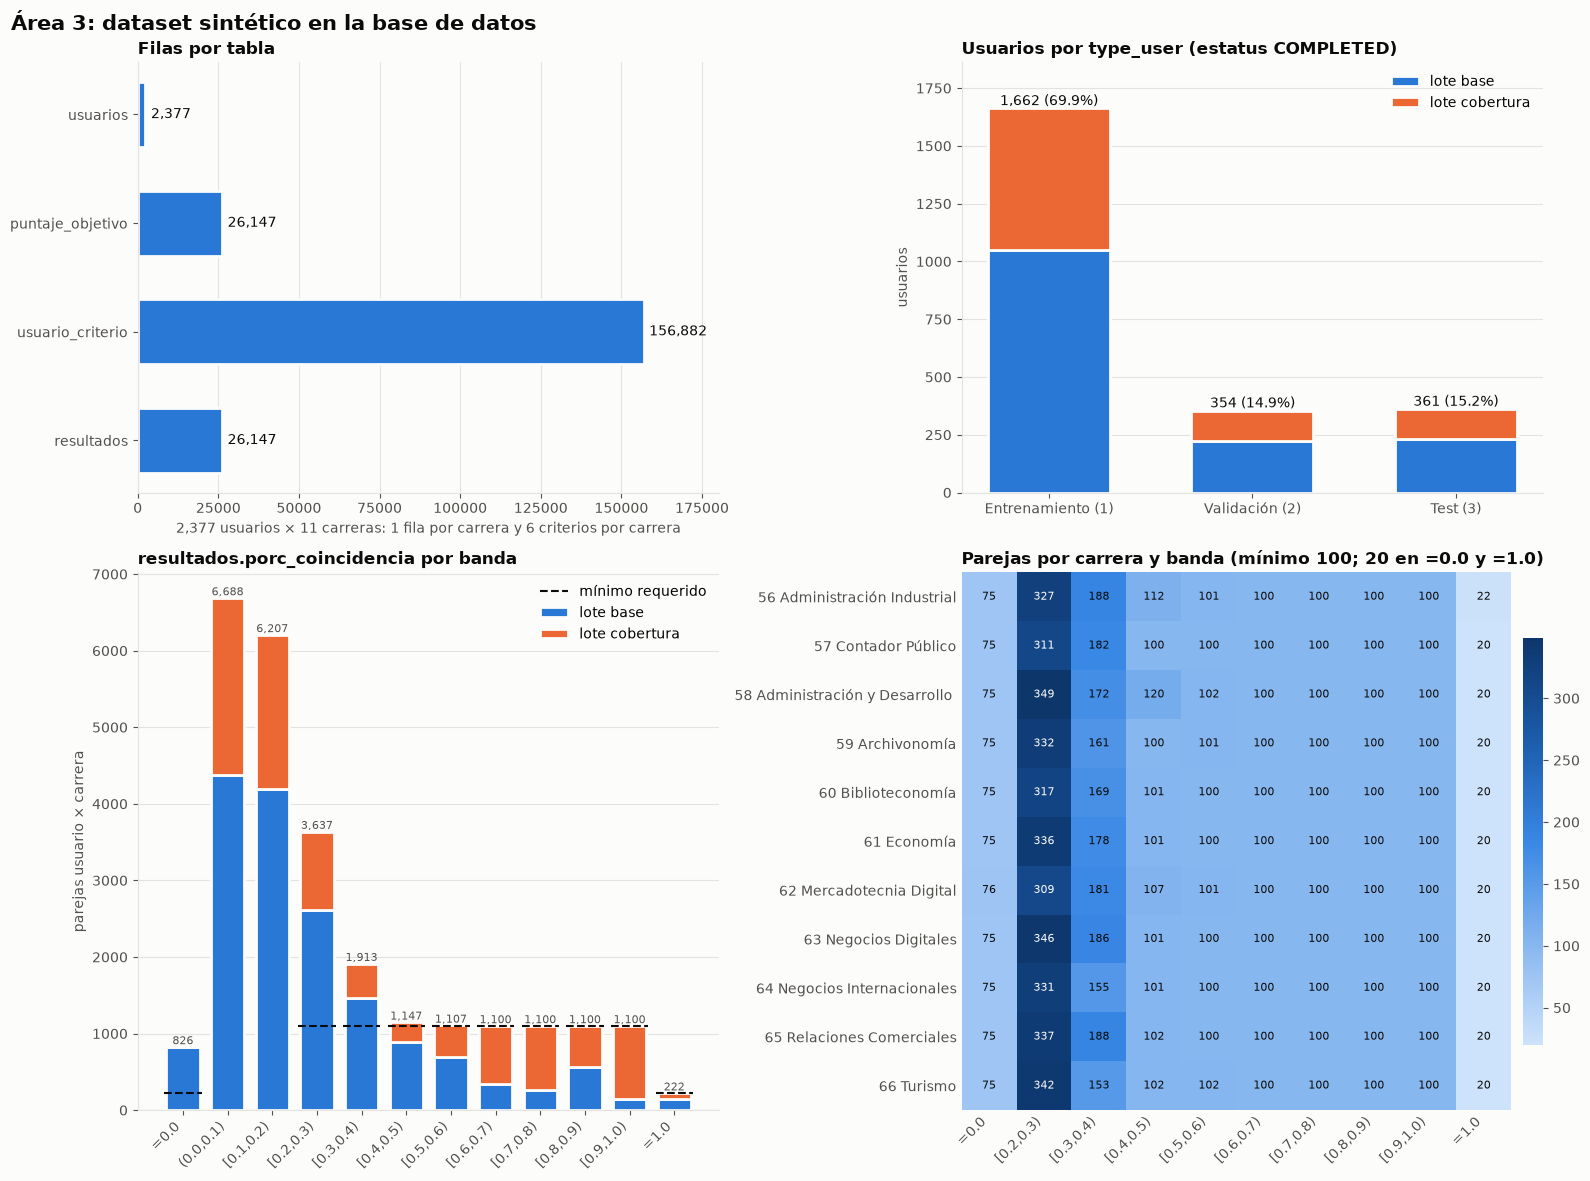

In [59]:
for area in LIST_AREAS:
    ds = gdt.datasets[area]
    if SUBIR_DB:
        usuarios, resultados, conteos = UploaderData(area).read_db()
    else:
        usuarios, resultados, conteos = ds["tablas"]["usuarios"], ds["tablas"]["resultados"], ds["conteos"]
    GraphData().plot(area, usuarios, resultados, conteos, ds["catalogo"])

In [ ]:
# UploaderData(1).delete(gdt.datasets[1]["tablas"]["usuarios"], confirmar=False)